# Retours et jours d'achat : peut-on se fier au `product_id` pour apparier un retour à son achat ?

**Question.** Aujourd'hui un « jour d'achat » est un couple (client, `date_order`) dont le **net du jour** (ventes − retours, tous produits confondus) dépasse 0,01 €. Cette définition peut se tromper de deux façons : un retour daté un autre jour que l'achat n'annule pas cet achat (le client reste « actif » à tort), et un retour d'un produit acheté ailleurs vient réduire le net d'achats sans rapport. Le dataset n'a pas de clé de commande, mais il a le `product_id`. Peut-on s'en servir pour rattacher chaque retour à son achat, et ça change-t-il quelque chose pour le churn ?

**Définitions.**

- **Retour** : une ligne avec `sales_net < 0` (la `quantity` est toujours positive, y compris sur les retours).
- **Événement** : un triplet (client, produit, `date_order`) ; on y somme achats (`sales_net > 0`) et retours (`sales_net < 0`).
- **Appariement « dernier achat »** : un retour est rattaché au **dernier achat du même client pour le même produit, à la même date ou avant** (jointure `ASOF`). Pas de fenêtre maximale imposée : c'est la mesure qui la donne (partie B).

**Parties.**

- **A.** Taille du phénomène et part des retours qui trouvent leur achat.
- **B.** Fenêtre de retour : délai entre l'achat et le retour. Vérification que les retours sans achat ne sont pas un effet de bord du début des données.
- **C.** Retours sans achat trouvé : que sont-ils ? Et la règle « dernier achat » est-elle ambiguë quand le retour n'est pas du jour ?
- **D.** Retour total ou partiel : quelle part de l'achat est reprise ?
- **E.** Impact sur la définition d'un jour d'achat et sur le label « aucun achat pendant 180 jours » : définition actuelle (net du jour) contre définition « par produit » (achat − retour apparié, retours sans achat ignorés).

Dates d'origine du dataset (`data/sales.parquet`, non décalé). Périmètre du dataset, non extrapolé.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"        # reproductibilité
from pathlib import Path
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", 50, "display.width", 220, "display.float_format", lambda x: f"{x:,.3f}")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PARQUET = ROOT / "data" / "sales.parquet"
con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
con.execute(f"SET temp_directory='{ROOT / 'data' / '.duckdb_tmp'}'")


def q(sql):
    return con.execute(sql).fetchdf()


C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a")
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"axes.facecolor": SURF, "figure.facecolor": SURF, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
                     "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

MIN_NET = 0.01                                   # seuil du jour d'achat (data.py : PURCHASE_DAY_MIN_NET)
LOOKBACK = 365                                   # recul minimal pour juger la fenêtre de retour (partie B)
FIRST_DAY = pd.Timestamp(q(f"SELECT min(date_order) AS m FROM read_parquet('{PARQUET}')").iloc[0, 0])
B_START = FIRST_DAY + pd.Timedelta(days=LOOKBACK)
DATES = [pd.Timestamp("2023-03-22") + pd.DateOffset(months=j) for j in range(13)]   # 22/03/2023 -> 22/03/2024
HIST, TRUTH = 180, 180

## Construction des tables

`ev` : un événement par (client, produit, jour), avec le montant et la quantité achetés et retournés ce jour-là. `m` : chaque événement de retour rattaché par `ASOF` à son **dernier achat** (même client, même produit, `date_achat ≤ date_retour`) ; `bd` vide = aucun achat trouvé.

In [2]:
t0 = time.time()
con.execute(f"CREATE OR REPLACE VIEW sales AS SELECT * FROM read_parquet('{PARQUET}')")
con.execute('''
CREATE OR REPLACE TABLE ev AS
SELECT client_id, product_id, date_order AS d,
       sum(sales_net)  FILTER (WHERE sales_net > 0) AS buy_amt,
       sum(quantity)   FILTER (WHERE sales_net > 0) AS buy_qty,
       sum(-sales_net) FILTER (WHERE sales_net < 0) AS ret_amt,
       sum(quantity)   FILTER (WHERE sales_net < 0) AS ret_qty
FROM sales WHERE sales_net <> 0 GROUP BY 1, 2, 3''')
con.execute('''
CREATE OR REPLACE TABLE m AS
SELECT r.client_id, r.product_id, r.d AS rd, r.ret_amt, r.ret_qty, b.d AS bd, b.buy_amt, b.buy_qty
FROM (SELECT * FROM ev WHERE ret_amt IS NOT NULL) r
ASOF LEFT JOIN (SELECT * FROM ev WHERE buy_amt IS NOT NULL) b
  ON r.client_id = b.client_id AND r.product_id = b.product_id AND r.d >= b.d''')
print(f"{time.time() - t0:.0f}s · premier jour des données : {FIRST_DAY:%d/%m/%Y} · retours jugés sur {LOOKBACK} j de recul à partir du {B_START:%d/%m/%Y}")

35s · premier jour des données : 22/09/2022 · retours jugés sur 365 j de recul à partir du 22/09/2023


## A. Taille du phénomène et part des retours qui trouvent leur achat

Trois cas pour un événement de retour : **même jour** (un achat du même produit, même client, le même jour), **jour antérieur** (le dernier achat est plus ancien), **aucun achat trouvé**.

In [3]:
lines = q('''
SELECT count(*) AS n, count(*) FILTER (WHERE sales_net < 0) AS n_neg,
       sum(sales_net) FILTER (WHERE sales_net > 0) AS pos, sum(-sales_net) FILTER (WHERE sales_net < 0) AS neg,
       count(*) FILTER (WHERE quantity <= 0) AS qty_nonpositive FROM sales''').iloc[0]
print(f"{lines.n:,.0f} lignes · {lines.n_neg:,.0f} retours ({100 * lines.n_neg / lines.n:.1f} % des lignes) · "
      f"retours = {100 * lines.neg / lines.pos:.1f} % du CA brut · lignes à quantité ≤ 0 : {lines.qty_nonpositive:,.0f}")

tabA = q('''
SELECT CASE WHEN bd IS NULL THEN '3. Aucun achat trouvé' WHEN bd = rd THEN '1. Même jour' ELSE '2. Jour antérieur' END AS "Achat apparié",
       count(*) AS "Événements de retour", sum(ret_amt) AS "Montant retourné (M€)"
FROM m GROUP BY 1 ORDER BY 1''').set_index("Achat apparié")
tabA["Part des événements (%)"] = 100 * tabA["Événements de retour"] / tabA["Événements de retour"].sum()
tabA["Part du montant (%)"] = 100 * tabA["Montant retourné (M€)"] / tabA["Montant retourné (M€)"].sum()
tabA["Montant retourné (M€)"] /= 1e6
tabA

63,319,315 lignes · 2,384,943 retours (3.8 % des lignes) · retours = 5.8 % du CA brut · lignes à quantité ≤ 0 : 0


,Événements de retour,Montant retourné (M€),Part des événements (%),Part du montant (%)
Achat apparié,,,,
1. Même jour,2227631,572.199,99.130,99.117
2. Jour antérieur,153,0.027,0.007,0.005
3. Aucun achat trouvé,19387,5.069,0.863,0.878


## B. Fenêtre de retour

Pour les retours **à partir de B_START** (au moins 365 jours de recul dans les données), le délai en jours entre le retour et son dernier achat apparié. Sans ce recul, un retour d'un achat antérieur au début des données serait faussement « sans achat » et le délai serait tronqué. Le second graphique suit la part de retours sans achat trouvé, mois par mois : un manque dû au début des données la ferait baisser avec le temps.

In [4]:
d = q(f'''
SELECT date_diff('day', bd, rd) AS delay, ret_amt FROM m WHERE bd IS NOT NULL AND rd >= DATE '{B_START:%Y-%m-%d}' ''')
n_all = q(f"SELECT count(*) AS n FROM m WHERE rd >= DATE '{B_START:%Y-%m-%d}'").iloc[0, 0]
bins = [-1, 0, 7, 30, 90, 180, 365, 10_000]
labels = ["Même jour", "1 à 7 j", "8 à 30 j", "31 à 90 j", "91 à 180 j", "181 à 365 j", "> 365 j"]
d["Délai"] = pd.cut(d.delay, bins, labels=labels)
tabB = d.groupby("Délai", observed=False).agg(**{"Événements": ("delay", "size"), "Montant (k€)": ("ret_amt", lambda s: s.sum() / 1e3)})
tabB["Part des retours appariés (%)"] = 100 * tabB["Événements"] / tabB["Événements"].sum()
print(f"{n_all:,} événements de retour après le {B_START:%d/%m/%Y} · {len(d):,} appariés ({100 * len(d) / n_all:.2f} %) · "
      f"délai max observé {d.delay.max()} j · quantiles 99 % / 99,9 % : {d.delay.quantile(.99):.0f} / {d.delay.quantile(.999):.0f} j")
print(f"retours appariés à un autre jour que le leur : {(d.delay > 0).sum():,} ({100 * (d.delay > 0).mean():.3f} %), "
      f"{d.ret_amt[d.delay > 0].sum():,.0f} € ({100 * d.ret_amt[d.delay > 0].sum() / d.ret_amt.sum():.3f} % du montant retourné apparié)")
tabB

1,135,227 événements de retour après le 22/09/2023 · 1,116,824 appariés (98.38 %) · délai max observé 559 j · quantiles 99 % / 99,9 % : 0 / 0 j
retours appariés à un autre jour que le leur : 146 (0.013 %), 26,130 € (0.009 % du montant retourné apparié)


,Événements,Montant (k€),Part des retours appariés (%)
Délai,,,
Même jour,1116678,"285,560.048",99.987
1 à 7 j,50,6.248,0.004
8 à 30 j,52,9.075,0.005
31 à 90 j,22,4.456,0.002
91 à 180 j,13,4.441,0.001
181 à 365 j,5,1.408,0.000
> 365 j,4,0.502,0.000


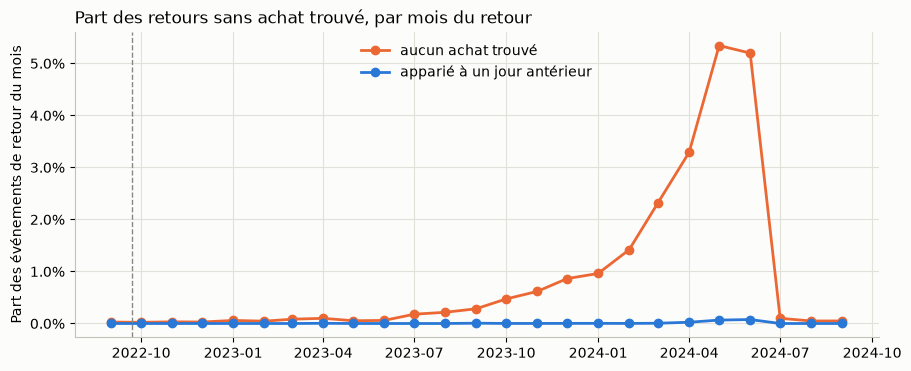

mois,2022-09-01,2022-10-01,2022-11-01,2022-12-01,2023-01-01,2023-02-01,2023-03-01,2023-04-01,2023-05-01,2023-06-01,2023-07-01,2023-08-01,2023-09-01,2023-10-01,2023-11-01,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01
n,"21,741.000","104,875.000","100,973.000","91,529.000","94,850.000","87,279.000","102,798.000","78,563.000","71,242.000","93,301.000","102,095.000","110,097.000","73,500.000","108,851.000","99,984.000","97,301.000","88,593.000","81,796.000","102,791.000","90,198.000","72,565.000","94,488.000","108,822.000","113,706.000","55,233.000"
part_sans_achat,0.030,0.020,0.030,0.030,0.060,0.040,0.080,0.100,0.050,0.060,0.180,0.220,0.280,0.470,0.620,0.860,0.960,1.420,2.330,3.290,5.340,5.200,0.100,0.050,0.050
part_jour_anterieur,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.010,0.000,0.000,0.000,0.000,0.000,0.000,0.020,0.070,0.080,0.000,0.000,0.000


In [5]:
mo = q('''
SELECT date_trunc('month', rd)::DATE AS mois, count(*) AS n, avg((bd IS NULL)::INT) AS part_sans_achat,
       avg((bd < rd)::INT) AS part_jour_anterieur
FROM m GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
ax.plot(mo.mois, 100 * mo.part_sans_achat, "o-", color=C["orange"], lw=2, label="aucun achat trouvé")
ax.plot(mo.mois, 100 * mo.part_jour_anterieur, "o-", color=C["blue"], lw=2, label="apparié à un jour antérieur")
ax.axvline(FIRST_DAY, color=MUTED, ls="--", lw=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set_ylabel("Part des événements de retour du mois")
ax.set_title("Part des retours sans achat trouvé, par mois du retour", loc="left")
ax.legend(frameon=False)
plt.show()
mo.assign(part_sans_achat=100 * mo.part_sans_achat, part_jour_anterieur=100 * mo.part_jour_anterieur).set_index("mois").T.round(2)

## C. Retours sans achat trouvé, et ambiguïté de la règle « dernier achat »

**C1.** Pour les retours sans achat à la date ou avant : le client a-t-il acheté ce produit **plus tard** (retour daté avant l'achat : décalage de dates) ou **jamais** dans les données ? Et ce retour tombe-t-il un jour où le client a acheté **autre chose** (le net du jour compense alors un achat sans rapport avec le retour) ?

**C2.** Pour les retours rattachés à un jour antérieur : combien d'achats candidats (même client, même produit) sur les 365 jours précédents ? Si un seul, la règle « dernier achat » n'a rien à trancher ; sinon, de combien de jours le premier candidat diffère-t-il du dernier ?

In [6]:
c1 = q('''
WITH u AS (SELECT * FROM m WHERE bd IS NULL),
later AS (SELECT DISTINCT u.client_id, u.product_id, u.rd FROM u
          JOIN ev e ON e.client_id = u.client_id AND e.product_id = u.product_id AND e.buy_amt IS NOT NULL AND e.d > u.rd),
other AS (SELECT DISTINCT u.client_id, u.product_id, u.rd FROM u
          JOIN ev e ON e.client_id = u.client_id AND e.d = u.rd AND e.product_id <> u.product_id AND e.buy_amt IS NOT NULL)
SELECT count(*) AS n, sum(u.ret_amt) AS amt,
       count(l.rd) AS n_later, count(o.rd) AS n_other_buy_same_day
FROM u LEFT JOIN later l USING (client_id, product_id, rd) LEFT JOIN other o USING (client_id, product_id, rd)''').iloc[0]
print(f"{c1.n:,.0f} événements sans achat trouvé ({c1.amt / 1e6:,.2f} M€) · "
      f"le client achète ce produit plus tard : {100 * c1.n_later / c1.n:.1f} % · "
      f"le client achète autre chose le jour même (le net du jour les compense) : {100 * c1.n_other_buy_same_day / c1.n:.1f} %")
lag = q('''
SELECT (u.bd IS NULL) AS sans_achat, count(*) AS lignes, median(date_diff('day', s.date_order, s.date_invoice)) AS delai_facture_median_j
FROM sales s JOIN m u ON s.client_id = u.client_id AND s.product_id = u.product_id AND s.date_order = u.rd
WHERE s.sales_net < 0 GROUP BY 1 ORDER BY 1''').set_index("sans_achat")
lag.index = ["Retour apparié", "Retour sans achat trouvé"]
lag

19,387 événements sans achat trouvé (5.07 M€) · le client achète ce produit plus tard : 37.2 % · le client achète autre chose le jour même (le net du jour les compense) : 100.0 %


,lignes,delai_facture_median_j
Retour apparié,2364536,17.000
Retour sans achat trouvé,20407,110.000


In [7]:
c2 = q(f'''
WITH x AS (SELECT * FROM m WHERE bd < rd),
cand AS (SELECT x.client_id, x.product_id, x.rd, x.bd, count(*) AS n_cand, min(e.d) AS first_d
         FROM x JOIN ev e ON e.client_id = x.client_id AND e.product_id = x.product_id AND e.buy_amt IS NOT NULL
                          AND e.d <= x.rd AND e.d >= x.rd - {LOOKBACK}
         GROUP BY 1, 2, 3, 4)
SELECT n_cand, date_diff('day', first_d, bd) AS spread FROM cand''')
print(f"{len(c2)} retours rattachés à un jour antérieur · un seul achat candidat : {100 * (c2.n_cand == 1).mean():.0f} % · "
      f"plusieurs candidats : {(c2.n_cand > 1).sum()} ; pour eux, écart médian / max entre le premier candidat et le dernier : "
      f"{c2.spread[c2.n_cand > 1].median():.0f} / {c2.spread[c2.n_cand > 1].max():.0f} j" if (c2.n_cand > 1).any() else "aucun cas ambigu")

149 retours rattachés à un jour antérieur · un seul achat candidat : 78 % · plusieurs candidats : 33 ; pour eux, écart médian / max entre le premier candidat et le dernier : 16 / 335 j


## D. Retour total ou partiel

Pour les retours appariés : montant retourné / montant acheté **par l'événement apparié** (même produit). `total` = 99 à 101 %, `partiel` = moins de 99 %, `supérieur` = plus de 101 % (le retour dépasse l'achat apparié : le reste vient d'un autre achat plus ancien ou d'un prix différent).

In [8]:
r = q('''
SELECT ret_amt / buy_amt AS ratio, ret_amt, buy_amt, abs(ret_qty - buy_qty) < 1e-9 AS same_qty, bd = rd AS same_day FROM m WHERE bd IS NOT NULL''')
r["Nature"] = pd.cut(r.ratio, [0, .99, 1.01, np.inf], labels=["Partiel (< 99 %)", "Total (99 à 101 %)", "Supérieur (> 101 %)"])
tabD = r.groupby("Nature", observed=False).agg(**{"Événements": ("ratio", "size"), "Montant retourné (M€)": ("ret_amt", lambda s: s.sum() / 1e6),
                                                  "Ratio médian (%)": ("ratio", lambda s: 100 * s.median())})
tabD["Part des événements (%)"] = 100 * tabD["Événements"] / tabD["Événements"].sum()
tabD["Part du montant (%)"] = 100 * tabD["Montant retourné (M€)"] / tabD["Montant retourné (M€)"].sum()
print(f"quantité retournée = quantité achetée : {100 * r.same_qty.mean():.1f} % des événements")
part = r[r.Nature == "Partiel (< 99 %)"]
print(f"retours partiels : restant net de l'achat apparié (médiane) = {100 * (1 - part.ratio).median():.0f} % ; "
      f"restant < 1 € dans {100 * ((part.buy_amt - part.ret_amt) < 1).mean():.1f} % des cas")
tabD

quantité retournée = quantité achetée : 80.1 % des événements
retours partiels : restant net de l'achat apparié (médiane) = 50 % ; restant < 1 € dans 3.4 % des cas


,Événements,Montant retourné (M€),Ratio médian (%),Part des événements (%),Part du montant (%)
Nature,,,,,
Partiel (< 99 %),509601,88.044,50.000,22.875,15.386
Total (99 à 101 %),1687175,468.277,100.000,75.733,81.834
Supérieur (> 101 %),31008,15.905,105.263,1.392,2.779


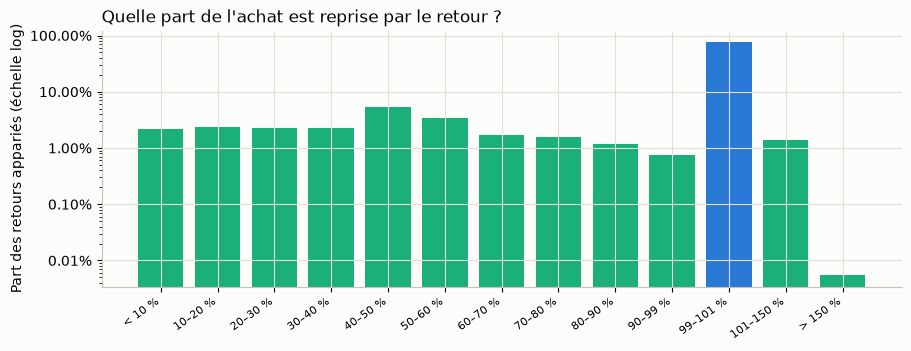

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.4), constrained_layout=True)
edges = np.r_[0, np.arange(0.1, 1.0, 0.1), 0.99, 1.01, 1.5, np.inf]
lab = ["< 10 %"] + [f"{int(100*a)}–{int(100*b)} %" for a, b in zip(np.arange(.1, .9, .1), np.arange(.2, 1.0, .1))] + ["90–99 %", "99–101 %", "101–150 %", "> 150 %"]
cnt = pd.cut(r.ratio, edges, include_lowest=True).value_counts(sort=False)
ax.bar(range(len(cnt)), 100 * cnt.values / cnt.sum(), color=[C["blue"] if "99–101" in l else C["aqua"] for l in lab])
ax.set_xticks(range(len(cnt)))
ax.set_xticklabels(lab, rotation=35, ha="right", fontsize=8)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=2))
ax.set_ylabel("Part des retours appariés (échelle log)")
ax.set_title("Quelle part de l'achat est reprise par le retour ?", loc="left")
plt.show()

## E. Impact sur la définition d'un jour d'achat et sur le label à 180 jours

Deux définitions du jour d'achat, toutes deux à seuil de 0,01 € :

- **Actuelle (net du jour)** : ventes − retours du client ce jour-là, **tous produits confondus**.
- **Par produit** : somme des achats du jour moins, pour chaque achat, le retour **apparié** à cet achat (plafonné au montant de l'achat), le retour étant imputé à la **date de l'achat**. Un retour sans achat trouvé est **ignoré** (il ne retire rien à des achats d'autres produits).

La seconde fait donc deux corrections : elle annule le bon jour quand le retour est daté plus tard, et elle ne laisse plus un retour sans achat connu réduire le net d'autres achats.

In [10]:
con.execute('''
CREATE OR REPLACE TABLE bn_cur AS
SELECT client_id, d, sum(coalesce(buy_amt, 0) - coalesce(ret_amt, 0)) AS net
FROM ev GROUP BY 1, 2 HAVING sum(coalesce(buy_amt, 0) - coalesce(ret_amt, 0)) > 0.01''')
con.execute('''
CREATE OR REPLACE TABLE bn_prod AS
WITH buys AS (SELECT client_id, d, sum(buy_amt) AS b FROM ev WHERE buy_amt IS NOT NULL GROUP BY 1, 2),
     rets AS (SELECT client_id, bd AS d, sum(least(ret_amt, buy_amt)) AS r FROM m WHERE bd IS NOT NULL GROUP BY 1, 2)
SELECT b.client_id, b.d, b.b - coalesce(r.r, 0) AS net
FROM buys b LEFT JOIN rets r USING (client_id, d) WHERE b.b - coalesce(r.r, 0) > 0.01''')
cmp_days = q('''
SELECT (SELECT count(*) FROM bn_cur) AS cur, (SELECT count(*) FROM bn_prod) AS prod,
       (SELECT count(*) FROM bn_cur c ANTI JOIN bn_prod p USING (client_id, d)) AS only_cur,
       (SELECT count(*) FROM bn_prod p ANTI JOIN bn_cur c USING (client_id, d)) AS only_prod''').iloc[0]
print(f"jours d'achat : actuelle {cmp_days.cur:,} · par produit {cmp_days['prod']:,} · "
      f"seulement dans l'actuelle {cmp_days.only_cur:,} ({100 * cmp_days.only_cur / cmp_days.cur:.3f} %) · "
      f"seulement par produit {cmp_days.only_prod:,} ({100 * cmp_days.only_prod / cmp_days.cur:.3f} %)")

jours d'achat : actuelle 7,792,993 · par produit 7,794,923 · seulement dans l'actuelle 5 (0.000 %) · seulement par produit 1,935 (0.025 %)


**Typologie des jours qui diffèrent.** « Seulement dans l'actuelle » : jours qui comptent comme achat alors que, produit par produit, tout est repris (ou reprise datée plus tard). « Seulement par produit » : jours exclus à tort de l'actuelle parce qu'un retour sans achat connu (autre produit, achat avant le début des données, etc.) a compensé de vrais achats.

In [11]:
typo = q('''
WITH ec AS (SELECT client_id, d, sum(buy_amt) AS buys, sum(ret_amt) AS rets FROM ev GROUP BY 1, 2),
uo AS (SELECT client_id, rd AS d, sum(ret_amt) AS unmatched FROM m WHERE bd IS NULL GROUP BY 1, 2),
xd AS (SELECT client_id, bd AS d, sum(ret_amt) FILTER (WHERE bd < rd) AS later_ret FROM m WHERE bd IS NOT NULL GROUP BY 1, 2),
a AS (SELECT 'Seulement dans l''actuelle' AS cas, client_id, d FROM bn_cur ANTI JOIN bn_prod USING (client_id, d)
      UNION ALL SELECT 'Seulement par produit', client_id, d FROM bn_prod ANTI JOIN bn_cur USING (client_id, d))
SELECT a.cas, count(*) AS jours, sum(coalesce(ec.buys, 0)) AS achats_bruts, sum(coalesce(ec.rets, 0)) AS retours_du_jour,
       sum((uo.unmatched IS NOT NULL)::INT) AS avec_retour_sans_achat, sum((xd.later_ret IS NOT NULL)::INT) AS avec_retour_d_un_autre_jour
FROM a LEFT JOIN ec USING (client_id, d) LEFT JOIN uo USING (client_id, d) LEFT JOIN xd USING (client_id, d)
GROUP BY 1 ORDER BY 1''').set_index("cas")
typo["achats_bruts"] /= 1e3
typo["retours_du_jour"] /= 1e3
typo = typo.rename(columns={"achats_bruts": "Achats bruts (k€)", "retours_du_jour": "Retours du jour (k€)", "jours": "Jours"})
typo

,Jours,Achats bruts (k€),Retours du jour (k€),avec_retour_sans_achat,avec_retour_d_un_autre_jour
cas,,,,,
Seulement dans l'actuelle,5,7.455,5.737,0.000,5.000
Seulement par produit,1935,"3,873.368","4,132.616","1,557.000",0.000


**Effet sur le churn.** À chaque date de photo T (13 photos mensuelles, du 22/03/2023 au 22/03/2024 : 180 jours de recul et 180 jours de vérité observables), sous chaque définition : clients **actifs** (au moins un jour d'achat dans les 180 jours avant T), parmi eux clients **partis** (aucun jour d'achat dans les 180 jours à partir de T). On compte les clients dont le statut diffère. Périmètre : tous les clients actifs, sans filtre sur le rythme.

In [12]:
def status(tab, T):
    t = f"{T:%Y-%m-%d}"
    return q(f'''
    SELECT client_id, TRUE AS active, NOT bool_or(d >= DATE '{t}') AS gone
    FROM {tab} WHERE d >= DATE '{t}' - {HIST} AND d < DATE '{t}' + {TRUTH}
    GROUP BY 1 HAVING bool_or(d < DATE '{t}')''').set_index("client_id")


rows = []
for T in DATES:
    a, b = status("bn_cur", T), status("bn_prod", T)
    j = a.merge(b, left_index=True, right_index=True, how="outer", suffixes=("_c", "_p"))
    act_c, act_p = j.active_c.fillna(False).astype(bool), j.active_p.fillna(False).astype(bool)
    gone_c, gone_p = j.gone_c.fillna(False).astype(bool), j.gone_p.fillna(False).astype(bool)
    rows.append({"Photo": f"{T:%d/%m/%Y}", "Actifs (actuelle)": int(act_c.sum()), "Actifs (par produit)": int(act_p.sum()),
                 "Partis (actuelle)": int(gone_c.sum()), "Partis (par produit)": int(gone_p.sum()),
                 "Clients au statut actif différent": int((act_c != act_p).sum()),
                 "Clients au statut parti différent": int((gone_c != gone_p).sum())})
tabE = pd.DataFrame(rows).set_index("Photo")
tabE["Écart sur les partis (%)"] = 100 * tabE["Clients au statut parti différent"] / tabE["Partis (actuelle)"]
tabE

,Actifs (actuelle),Actifs (par produit),Partis (actuelle),Partis (par produit),Clients au statut actif différent,Clients au statut parti différent,Écart sur les partis (%)
Photo,,,,,,,
22/03/2023,119738,119745,21989,21988,7,7,0.032
22/04/2023,118627,118632,21363,21366,5,5,0.023
22/05/2023,115733,115737,19238,19241,4,5,0.026
22/06/2023,115948,115954,19291,19294,6,7,0.036
22/07/2023,116767,116777,20055,20059,10,8,0.040
22/08/2023,117917,117926,21257,21257,9,12,0.056
22/09/2023,118009,118016,22095,22088,7,19,0.086
22/10/2023,118381,118385,22511,22489,4,26,0.115
22/11/2023,120479,120486,25139,25112,7,33,0.131


## Conclusions

1. **Les retours sont presque tous datés le jour de l'achat, ce qui contredit l'hypothèse de départ.** Sur 2,25 M d'événements de retour (client × produit × jour), **99,13 %** ont un achat du même produit par le même client **le même jour**. Seuls **153** (0,007 %, 27 k€) se rattachent à un jour antérieur. Le net du jour par client ne rate donc presque jamais l'annulation d'un achat par un retour daté plus tard.
2. **Fenêtre de retour mesurée : elle est de fait nulle.** À partir du 22/09/2023 (365 jours de recul), 99,987 % des retours appariés tombent le jour même. Parmi les 146 retours d'un autre jour, 70 % ont lieu dans les 30 jours, 85 % dans les 90 jours, 94 % dans les 180 jours ; le délai maximal observé est de 559 jours. Aucune fenêtre n'est à paramétrer.
3. **La règle « dernier achat » est sans enjeu.** Sur les 149 retours d'un jour antérieur, 78 % n'ont qu'**un seul** achat candidat sur 365 jours. Pour les 33 autres, l'écart médian entre le premier candidat et le dernier est de 16 jours (max 335). Cela concerne 33 événements sur 2,25 M.
4. **Retours totaux et partiels.** 75,7 % des événements reprennent l'achat apparié en totalité (82 % du montant), 22,9 % en partie (15 % du montant, la moitié de l'achat en médiane), 1,4 % pour plus de 101 % de l'achat. Un retour partiel laisse donc dans 3 cas sur 4 un vrai achat net : la définition actuelle les traite correctement (un net de 5 € sur 100 € est bien un jour d'achat).
5. **Le vrai résidu : 19 387 retours (0,86 % des événements, 5,1 M€) sans achat trouvé, et il n'est pas stable.** La part passe de 0,03 % en 2022 à 0,2 % en juillet 2023, puis monte à 5 % en juin 2024 avant de retomber à 0,1 % dès juillet 2024. Ce n'est donc pas un effet de début de données (il baisserait avec le temps). Ces retours sont facturés avec un délai médian de **110 jours** après la date de commande, contre 17 jours pour les autres (tableau de la partie C), 37 % des clients rachètent ce produit plus tard, et 100 % de ces retours tombent un jour où le client achète autre chose. Lecture probable : des avoirs émis tardivement dont l'achat d'origine est hors du périmètre extrait. **À confirmer avec le client** (origine des avoirs, périmètre de l'extraction).
6. **Effet sur la définition d'un jour d'achat : négligeable à ce stade.** La définition « par produit » donne 7 794 923 jours d'achat contre 7 792 993 pour la définition actuelle (+0,025 %). Les 1 935 jours en plus sont des jours où un retour sans achat connu compensait de vrais achats d'autres produits (1 557 d'entre eux). Seuls 5 jours disparaissent. Sur le label « aucun achat pendant 180 jours », le statut parti change pour **5 à 45 clients par photo**, soit 0,03 % à 0,21 % des partis.
7. **Une tendance à surveiller.** L'écart sur les partis monte de 0,03 % (mars 2023) à 0,21 % (mars 2024), en même temps que la part de retours sans achat. Il suit la part de retours sans achat, et les photos les plus récentes sont celles où il pèse le plus. Il reste très inférieur au bruit d'entraînement mesuré (0,3 à 2 points de CA capté).

**Décision proposée.** Garder la définition actuelle (net du jour, seuil 0,01 €) : le `product_id` ne change rien d'utile au churn, et l'appariement par `ASOF` ne se justifie pas dans `src/churn/`. À faire en revanche : poser la question des avoirs tardifs au client avant le passage en production, et relancer ce notebook si l'extraction est actualisée.